2180/2180 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step


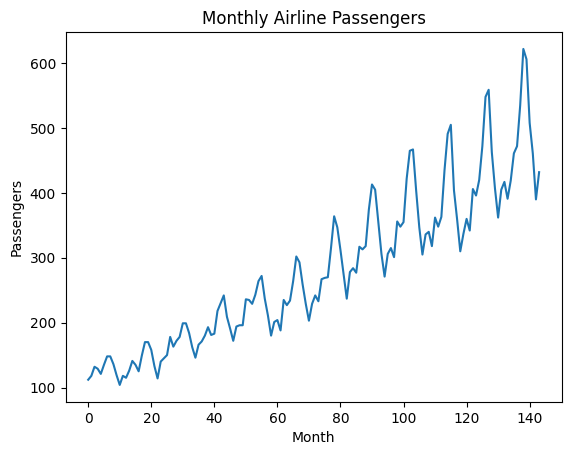

SimpleRNN: Train RMSE = 11.98, Test RMSE = 30.16


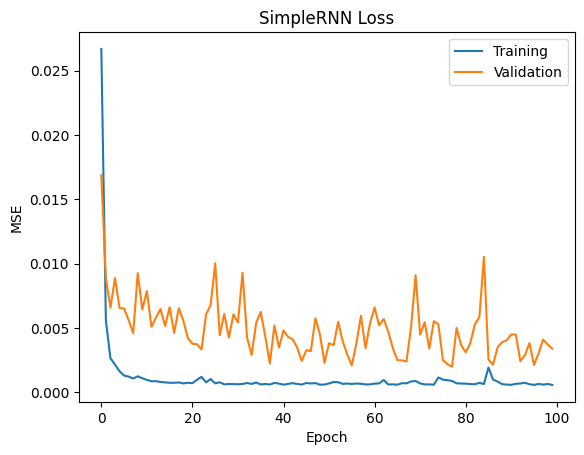

LSTM: Train RMSE = 18.20, Test RMSE = 55.15


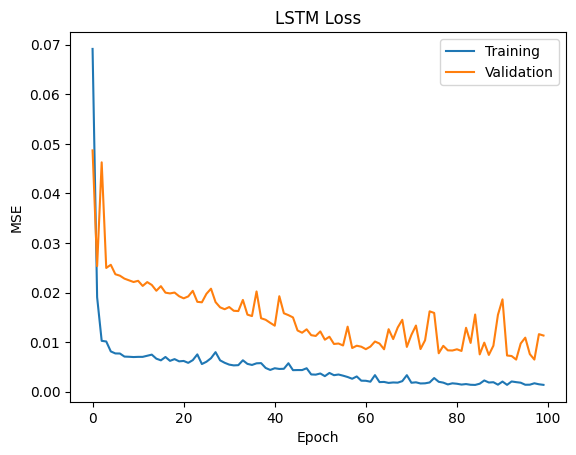

GRU: Train RMSE = 22.18, Test RMSE = 37.89


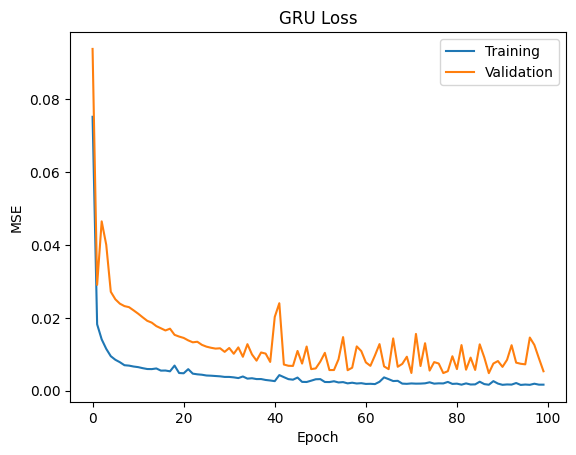

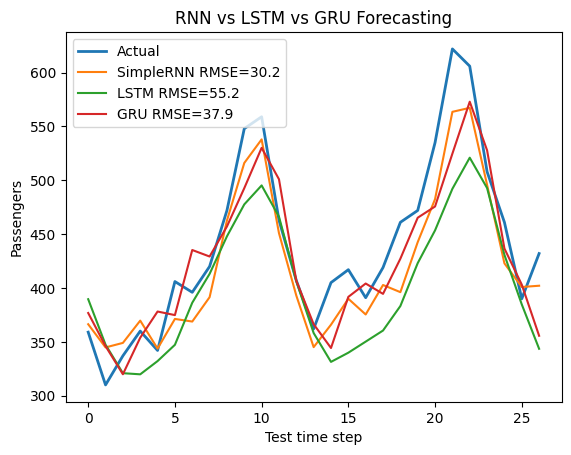


Final comparison:
SimpleRNN: 30.16 RMSE
LSTM: 55.15 RMSE
GRU: 37.89 RMSE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.utils import get_file
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# 1. Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
path = get_file("airline-passengers.csv", origin=url)

df = pd.read_csv(path)
data = df["Passengers"].values.reshape(-1, 1).astype("float32")

plt.plot(data)
plt.title("Monthly Airline Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.savefig("raw_series.png")
plt.show()

# 2. Normalize data
scaler = MinMaxScaler()
data = scaler.fit_transform(data)

# 3. Create sequences: previous 12 months -> next month
LOOK_BACK = 12
X, y = [], []

for i in range(len(data) - LOOK_BACK):
    X.append(data[i:i + LOOK_BACK])
    y.append(data[i + LOOK_BACK])

X = np.array(X)
y = np.array(y)

# Chronological 80:20 split
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 4. Build all three models
models = {
    "SimpleRNN": SimpleRNN(50, activation="tanh"),
    "LSTM": LSTM(50, activation="tanh"),
    "GRU": GRU(50, activation="tanh")
}

results = {}

# 5. Train and evaluate each model
for name, layer in models.items():

    model = Sequential([
        Input(shape=(LOOK_BACK, 1)),
        layer,
        Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse")

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=100,
        batch_size=8,
        verbose=0
    )

    # Predictions
    train_pred = model.predict(X_train, verbose=0)
    test_pred = model.predict(X_test, verbose=0)

    # Convert back to passenger counts
    train_pred = scaler.inverse_transform(train_pred)
    test_pred = scaler.inverse_transform(test_pred)
    actual_train = scaler.inverse_transform(y_train)
    actual_test = scaler.inverse_transform(y_test)

    # Calculate RMSE
    train_rmse = np.sqrt(mean_squared_error(actual_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(actual_test, test_pred))

    results[name] = (test_pred, test_rmse)

    print(f"{name}: Train RMSE = {train_rmse:.2f}, "
          f"Test RMSE = {test_rmse:.2f}")

    # Save loss curve
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.legend()
    plt.savefig(name.lower() + "_loss.png")
    plt.show()
    plt.close()

# 6. Compare forecasts
plt.plot(actual_test, label="Actual", linewidth=2)

for name, (prediction, rmse) in results.items():
    plt.plot(prediction, label=f"{name} RMSE={rmse:.1f}")

plt.title("RNN vs LSTM vs GRU Forecasting")
plt.xlabel("Test time step")
plt.ylabel("Passengers")
plt.legend()
plt.savefig("rnn_vs_lstm_forecast.png")
plt.show()

print("\nFinal comparison:")
for name, (_, rmse) in results.items():
    print(f"{name}: {rmse:.2f} RMSE")
